Testing the performance of these as new category data. 
    - Will need to add new functions to the model_building class
    - With the option to categorize these values....
    - Or just restrict these new classes to this notebook.

Test these as nominal and as ordinal categories.

* exclbreastfed - either turn it nominal or re-categorize: 5 values: never, 1-3months, 4-5months, 6months and above
* totalbreastfed - either turn it nominal or re-categorize: 2 values: 0-6months, 6months and above (binary)
* tobacco -> turn it into nominal data or turn it into 4 categories: daily, less than daily, never.
* *admitabx_adm_8 -> find other features that correlate with this one.

In [4]:
import numpy as np
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder


class CustomIterativeImputer:
    def __init__(self, max_iter=10, random_state=42):

        ####################################################################
        ### Mode, medians and catch-all for default values               ###
        ####################################################################
        self.mode_values = {}
        self.mode_traveldist = None
        self.mode_momage_per_children_group = None
        self.mode_momage_firstpreg_per_children_group = None

        # medians by age group
        self.medians_by_age_group = {}
        self.age_bins = [0, 2, 5, 11, 23, 35, 47, 59, 65]
        self.age_labels = [
            0,  # 'Newborn (0-2m)'
            1,  # 'Infant (3-5m)'
            2,  # 'Baby (6-11m)'
            3,  # 'Toddler (12-23m)'
            4,  # 'Preschool-2 (24-35m)'
            5,  # 'Preschool-3 (36-47m)'
            6,  # 'Preschool-4 (48-59m)'
            7,  # '5 years (60m)'
        ]

        # default values
        self.default_values = {
            'exclbreastfed_adm': 'Unknown',
            'totalbreastfed_adm': 'Unknown',
            'vaccmeaslessource_adm': 'Self report',
            'vaccpneumocsource_adm': 'Self report',
            'vaccdptsource_adm': 'Self report',
            'vaccpneumoc_adm': 'Unknown',
            'vaccmeasles_adm': 'Unknown',
            'vaccdpt_adm': 'Unknown',
            'priorweekantimal_adm': 'Dont know',
            'priorhosp_adm': 'Dont know',
            'prioryearwheeze_adm': 'Dont know',
            'travelmethod_adm': 'Other',
            'badhealthduration_adm': 'Unknown',
            'caregiver_adm_new': 'Other',
            'momhiv_adm': 'Unknown',
            'lightfuel_adm': 'Other',
            'momagefirstpregknown_adm': 'No',
            'waterpure_adm': 'No',
            'bednet_adm': 'Never',
            'deadchildren_adm': 0.0,
            'alivechildren_adm': 1.0}

        # store no default values
        self.no_default_features = ['traveldist_adm', 'caregiverage_adm', 'caregivermarried_adm',
                                    'momalive_adm', 'momageknown_adm', 'momedu_adm', 'watersource_adm', 'cookfuel_adm___1',
                                    'cookfuel_adm___2', 'cookfuel_adm___3', 'cookfuel_adm___4', 'cookfuel_adm___5', 'cookfuel_adm___6',
                                    'cookfuel_adm___7', 'cookfuel_adm___8', 'cookloc_adm', 'tobacco_adm', 'momage_adm', 'momagefirstpreg_adm',
                                    'householdsize_adm']

        # numerical features
        self.numeric_columns = ['height_cm_adm', 'agecalc_adm', 'weight_kg_adm', 'muac_mm_adm',
                                'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm', 'diasbp_mmhg_adm', 'temp_c_adm',
                                'spo2site1_pc_oxi_adm', 'spo2site2_pc_oxi_adm', 'spo2other_adm', 'hematocrit_gpdl_adm',
                                'lactate_mmolpl_adm', 'lactate2_mmolpl_adm', 'glucose_mmolpl_adm', 'sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm',
                                'momage_adm', 'momagefirstpreg_adm', 'householdsize_adm', 'alivechildren_adm', 'deadchildren_adm']

        ########################################################################
        ### Imputers for Continuous Data (mostly clinical and laboratory)    ###
        ########################################################################

        self.label_encoder_sex_adm = LabelEncoder()

        # Dictionary of standard values for continuous imputers
        self.standard_values = {
            # https://myhealth.alberta.ca/Health/pages/conditions.aspx?hwid=abo2987&lang=en-ca#abo2987-Bib
            'standard_low_hr_bpm_adm': {0: 70, 1: 70, 2: 70, 3: 52, 4: 52, 5: 52, 6: 52, 7: 52},
            'standard_high_hr_bpm_adm': {0: 190, 1: 190, 2: 190, 3: 156, 4: 156, 5: 156, 6: 156, 7: 156},

            # https://www.healthlinkbc.ca/healthwise/vital-signs-children
            # https://myhealth.alberta.ca/Health/pages/conditions.aspx?hwid=abo2987
            'standard_low_rr_brpm_app_adm': {0: 25, 1: 25, 2: 22, 3: 21, 4: 21, 5: 17, 6: 17, 7: 17},
            'standard_high_rr_brpm_app_adm': {0: 64, 1: 64, 2: 61, 3: 33, 4: 33, 5: 25, 6: 25, 7: 25},

            # https://medicine.uiowa.edu/iowaprotocols/pediatric-vital-signs-normal-ranges
            # https://www.childrensmercy.org/siteassets/media-documents-for-depts-section/documents-for-health-care-providers/..
            # evidence-based-practice/clinical-practice-guidelines--care-process-models/normal-blood-pressures-by-age.pdf
            'standard_low_sysbp_mmhg_adm': {0: 60, 1: 78,  2: 82, 3: 85, 4: 89, 5: 90, 6: 92, 7: 93},
            'standard_high_sysbp_mmhg_adm': {0: 94, 1: 103,  2: 105, 3: 102, 4: 106, 5: 107, 6: 108, 7: 110},
            'standard_low_diasbp_mmhg_adm': {0: 30, 1: 44,  2: 45, 3: 41, 4: 44, 5: 47, 6: 50, 7: 53},
            'standard_high_diasbp_mmhg_adm': {0: 56, 1: 65,  2: 68, 3: 58, 4: 62, 5: 65, 6: 67, 7: 70},

            # https://www.accp.com/docs/sap/Lab_values_Table_PedSAP.pdf
            'standard_low_hematocrit_gpdl_adm': {0: 44, 1: 32, 2: 32, 3: 32, 4: 33, 5: 33, 6: 33, 7: 33},
            'standard_high_hematocrit_gpdl_adm': {0: 70, 1: 42, 2: 42, 3: 42, 4: 43, 5: 43, 6: 43, 7: 43},
        }
        self.imputer_group_0 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_0 = ['agecalc_adm',
                                 'height_cm_adm', 'weight_kg_adm', 'muac_mm_adm']

        self.imputer_group_1 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_1 = ['hr_bpm_adm',
                                 'rr_brpm_app_adm',
                                 'temp_c_adm',
                                 'height_cm_adm',
                                 'age_group',
                                 'standard_low_hr_bpm_adm',
                                 'standard_high_hr_bpm_adm',
                                 'standard_low_rr_brpm_app_adm',
                                 'standard_high_rr_brpm_app_adm']

        self.imputer_group_2 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_2 = ['sysbp_mmhg_adm',
                                 'diasbp_mmhg_adm',
                                 'hr_bpm_adm',
                                 'sex_adm',
                                 'age_group',
                                 'standard_low_sysbp_mmhg_adm',
                                 'standard_high_sysbp_mmhg_adm',
                                 'standard_low_diasbp_mmhg_adm',
                                 'standard_high_diasbp_mmhg_adm']

        self.imputer_group_3 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_3 = ['spo2site1_pc_oxi_adm',
                                 'spo2site2_pc_oxi_adm',
                                 'spo2other_adm',
                                 'hr_bpm_adm',
                                 'rr_brpm_app_adm']

        self.imputer_group_4 = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_4 = ['hematocrit_gpdl_adm',
                                 'glucose_mmolpl_adm',
                                 'lactate_mmolpl_adm',
                                 'lactate2_mmolpl_adm',
                                 'rr_brpm_app_adm',
                                 'age_group',
                                 'standard_low_hematocrit_gpdl_adm',
                                 'standard_high_hematocrit_gpdl_adm']

        ########################################################################
        ### Imputers for Categorical Data (mostly clinical and laboratory)   ###
        ########################################################################

        # Initialize IterativeImputer with default configuration
        self.ordinal_encoder = OrdinalEncoder(
            handle_unknown='use_encoded_value', unknown_value=np.nan)
        self.categorical_cols = ['hivstatus_adm', 'malariastatuspos_adm', 'hctpretransfusion_adm',
                                 'spo2onoxy_adm', 'oxygenavail_adm', 'respdistress_adm',
                                 'bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm', 'symptoms_adm___14',
                                 'feedingstatus_adm', 'deliveryloc_adm', 'birthattend_adm',
                                 'caprefill_adm', 'hr_bpm_adm', 'weight_kg_adm',
                                 'vaccmeaslessource_adm', 'vaccpneumocsource_adm', 'vaccdptsource_adm',
                                 'vaccmeasles_adm', 'vaccpneumoc_adm', 'vaccdpt_adm',
                                 'momhiv_adm']
        self.imputer_group_A = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_A = ['hivstatus_adm',
                                 'lactate_mmolpl_adm', 'momhiv_adm']
        self.imputer_group_B = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_B = [
            'malariastatuspos_adm', 'hctpretransfusion_adm', 'lactate_mmolpl_adm', 'hematocrit_gpdl_adm']
        self.imputer_group_C = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_C = ['spo2onoxy_adm',
                                 'oxygenavail_adm', 'respdistress_adm']
        self.imputer_group_D = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_D = ['bcseye_adm', 'bcsmotor_adm',
                                 'bcsverbal_adm', 'symptoms_adm___14', 'feedingstatus_adm']
        self.imputer_group_E = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_E = ['deliveryloc_adm', 'birthattend_adm']
        self.imputer_group_F = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_F = [
            'caprefill_adm', 'hr_bpm_adm', 'weight_kg_adm']
        self.imputer_group_G = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_G = ['vaccmeasles_adm',
                                 'vaccpneumoc_adm', 'vaccdpt_adm']
        self.imputer_group_H = IterativeImputer(
            max_iter=max_iter, random_state=random_state)
        self.features_group_H = ['vaccmeaslessource_adm',
                                 'vaccpneumocsource_adm', 'vaccdptsource_adm']

    def fit(self, X_train: pd.DataFrame, y_train=None):
        """Fits the imputer on training data."""
        X = X_train.copy()
        # Drop unnecessary columns
        X.drop(columns=['studyid_adm', 'lengthadm'],
               errors='ignore', inplace=True)

        try:
            X[self.numeric_columns] = X[self.numeric_columns].apply(
                pd.to_numeric)
        except Exception as e:
            print(e)

        # Define age groups
        X['age_group'] = pd.cut(
            X['agecalc_adm'],
            bins=self.age_bins,
            labels=self.age_labels,
            right=True)

        ########################################################################
        ### Imputers for Continuous Data (mostly clinical and laboratory)    ###
        ########################################################################

        # Map standard values
        X = self._map_standard_values(X)

        # encode the sex_adm feature
        X['sex_adm'] = X['sex_adm'].astype(object)
        self.label_encoder_sex_adm.fit(X['sex_adm'])
        X['sex_adm'] = self.label_encoder_sex_adm.transform(X['sex_adm'])

        # fit/train the imputer
        self.imputer_group_0.fit(X[self.features_group_0])
        self.imputer_group_1.fit(X[self.features_group_1])
        self.imputer_group_2.fit(X[self.features_group_2])
        self.imputer_group_3.fit(X[self.features_group_3])
        self.imputer_group_4.fit(X[self.features_group_4])

        ########################################################################
        ### Imputers for Categorical Data (mostly clinical and laboratory)   ###
        ########################################################################

        # Preserve NaN values and fit the OrdinalEncoder
        X[self.categorical_cols] = X[self.categorical_cols].astype(object)
        self.ordinal_encoder.fit(X[self.categorical_cols])
        X[self.categorical_cols] = self.ordinal_encoder.transform(
            X[self.categorical_cols])

        # Fit the imputers
        self.imputer_group_A.fit(X[self.features_group_A])
        self.imputer_group_B.fit(X[self.features_group_B])
        self.imputer_group_C.fit(X[self.features_group_C])
        self.imputer_group_D.fit(X[self.features_group_D])
        self.imputer_group_E.fit(X[self.features_group_E])
        self.imputer_group_F.fit(X[self.features_group_F])
        self.imputer_group_G.fit(X[self.features_group_G])
        self.imputer_group_H.fit(X[self.features_group_H])

        ########################################################################
        ### Mode, medians and catch-all for default values                   ###
        ########################################################################

        # fill the mode values
        for col in self.no_default_features:
            self.mode_values[col] = X[col].mode()[0]
        self.mode_traveldist = X.groupby('travelmethod_adm')['traveldist_adm'].agg(
            lambda x: x.mode()[0] if not x.mode().empty else None)
        X['number_of_children'] = X['alivechildren_adm'] + X['deadchildren_adm']
        self.mode_momage_per_children_group = X.groupby('number_of_children')['momage_adm'].apply(
            lambda x: x.mode()[0] if not x.mode().empty else None)
        self.mode_momage_firstpreg_per_children_group = X.groupby(['momage_adm', 'number_of_children'])['momagefirstpreg_adm'].apply(
            lambda x: x.mode()[0] if not x.mode().empty else None)
        self.mode_momage_firstpreg_per_children_group = self.mode_momage_firstpreg_per_children_group.fillna(
            method='ffill').fillna(method='bfill')

        # Compute medians for numerical columns by age group
        columns_to_fill_by_median = []

        for column in columns_to_fill_by_median:
            self.medians_by_age_group[column] = X.groupby('age_group')[
                column].median()

    def transform(self, X_test: pd.DataFrame, y_test=None):
        """Fits the imputer on training data."""
        X = X_test.copy()
        # Drop unnecessary columns
        X.drop(columns=['studyid_adm', 'lengthadm'],
               errors='ignore', inplace=True)

        try:
            X[self.numeric_columns] = X[self.numeric_columns].apply(
                pd.to_numeric)
        except Exception as e:
            print(e)

        # Define age groups
        X['age_group'] = pd.cut(
            X['agecalc_adm'],
            bins=self.age_bins,
            labels=self.age_labels,
            right=True)

        ########################################################################
        ### Imputers for Continuous Data (mostly clinical and laboratory)    ###
        ########################################################################

        # Map standard values
        X = self._map_standard_values(X)

        # encode the sex_adm feature
        X['sex_adm'] = X['sex_adm'].astype(object).to_frame()
        X['sex_adm'] = self.label_encoder_sex_adm.transform(X['sex_adm'])

        # imputer transformation
        X[self.features_group_0] = self.imputer_group_0.transform(
            X[self.features_group_0])
        X[self.features_group_1] = self.imputer_group_1.transform(
            X[self.features_group_1])
        X[self.features_group_2] = self.imputer_group_2.transform(
            X[self.features_group_2])
        X[self.features_group_3] = self.imputer_group_3.transform(
            X[self.features_group_3])
        X[self.features_group_4] = self.imputer_group_4.transform(
            X[self.features_group_4])

        # Drop unnecessary columns
        X.drop(columns=self.standard_values.keys(),
               inplace=True, errors='ignore')

        # Inverse transform sex_adm feature
        X['sex_adm'] = self.label_encoder_sex_adm.inverse_transform(
            np.round(X['sex_adm']).astype(int))

        ########################################################################
        ### Imputers for Categorical Data (mostly clinical and laboratory)   ###
        ########################################################################

        # Apply categorization for 'exclbreastfed_adm' based on 'agecalc_adm'
        X['exclbreastfed_adm'] = X[['exclbreastfed_adm', 'agecalc_adm']].apply(
            self._categorize_breastfeeding, axis=1)

        # Apply categorization for 'totalbreastfed_adm' based on 'agecalc_adm'
        X['totalbreastfed_adm'] = X[['totalbreastfed_adm', 'agecalc_adm']].apply(
            self._categorize_total_breastfeeding, axis=1)

        # Apply categorization for 'nonexclbreastfed_adm' based on 'exclbreastfed_adm'
        X['nonexclbreastfed_adm'] = X[['nonexclbreastfed_adm', 'exclbreastfed_adm']].apply(
            self._categorize_non_exlc_breastfeeding, axis=1)
        


        # 
        X['exclbreastfed_adm'] = X[['exclbreastfed_adm', 'agecalc_adm']].apply(
            self._recategorize_exclbreastfeeding, axis=1)

        # 
        X['totalbreastfed_adm'] = X[['totalbreastfed_adm', 'agecalc_adm']].apply(
            self._recategorize_total_breastfeeding, axis=1)

        # 
        X['tobacco_adm'] = X[['tobacco_adm', 'agecalc_adm']].apply(
            self._recategorize_tobacco, axis=1)
        
        
        


        # Transform categorical columns while preserving NaNs
        X[self.categorical_cols] = X[self.categorical_cols].astype(object)
        X[self.categorical_cols] = self.ordinal_encoder.transform(
            X[self.categorical_cols])

        # Impute missing values
        X[self.features_group_A] = self.imputer_group_A.transform(
            X[self.features_group_A])
        X[self.features_group_B] = self.imputer_group_B.transform(
            X[self.features_group_B])
        X[self.features_group_C] = self.imputer_group_C.transform(
            X[self.features_group_C])
        X[self.features_group_D] = self.imputer_group_D.transform(
            X[self.features_group_D])
        X[self.features_group_E] = self.imputer_group_E.transform(
            X[self.features_group_E])
        X[self.features_group_F] = self.imputer_group_F.transform(
            X[self.features_group_F])
        X[self.features_group_G] = self.imputer_group_G.transform(
            X[self.features_group_G])
        X[self.features_group_H] = self.imputer_group_H.transform(
            X[self.features_group_H])

        # Inverse transform categorical columns
        X[self.categorical_cols] = self.ordinal_encoder.inverse_transform(
            X[self.categorical_cols])

        ########################################################################
        ### Mode, medians and catch-all for default values                   ###
        ########################################################################

        X['momageknown_adm'] = np.where(X['momage_adm'].notna(), "Yes", "No")
        X['traveldist_adm'] = X['traveldist_adm'].fillna(
            X['travelmethod_adm'].map(self.mode_traveldist))

        X.loc[X['momalive_adm'].isna(), 'momalive_adm'] = X.loc[
            X['momalive_adm'].isna(), 'caregiver_adm_new'].apply(
                lambda x: 'Yes' if x == 'Mother' else 'No')
        X['number_of_children'] = X['alivechildren_adm'] + X['deadchildren_adm']
        X['momage_adm'] = X['momage_adm'].fillna(
            X['number_of_children'].map(self.mode_momage_per_children_group))
        X['momagefirstpreg_adm'] = X.apply(
            lambda row: self.mode_momage_firstpreg_per_children_group.loc[
                (row['momage_adm'], row['number_of_children'])]
            if pd.isna(row['momagefirstpreg_adm']) else row['momagefirstpreg_adm'], axis=1)
        X['caregiverage_adm'] = X['momage_adm'].where(
            X['caregiver_adm_new'] == 'Mother',
            self.mode_values["caregiverage_adm"])
        X.drop(columns=['number_of_children'], inplace=True)

        # Fill missing values by median of age groups
        for column, medians in self.medians_by_age_group.items():
            X[column] = X.apply(
                lambda row: medians[row['age_group']] if pd.isnull(
                    row[column]) else row[column],
                axis=1
            )

        # catch-all to fill all missing values based on mode and default values
        for col, mode_value in self.mode_values.items():
            X[col].fillna(mode_value, inplace=True)
        X.fillna(self.default_values, inplace=True)

        return X

    def fit_transform(self, X):
        """
        Combines fit and transform methods.
        """
        self.fit(X)
        return self.transform(X)

    ###############################################################
    #################### Helper Functions #########################
    ###############################################################

    def _map_standard_values(self, X: pd.DataFrame) -> pd.DataFrame:
        """Helper function to map standard values based on age group."""
        for column, mapping in self.standard_values.items():
            X[column] = X['age_group'].map(mapping)
        return X

    def _categorize_breastfeeding(self, row):
        if row['exclbreastfed_adm'] == "Currently exclusively breastfed":
            age_in_months = np.ceil(row['agecalc_adm'])
            if age_in_months <= 1:
                return "1 month"
            elif age_in_months <= 6:
                return f"{int(age_in_months)} months"
            else:
                return "More than 6 months"
        else:
            return row['exclbreastfed_adm']

    def _categorize_total_breastfeeding(self, row):
        if row['totalbreastfed_adm'] == "Still being breastfed":
            age_in_months = np.ceil(row['agecalc_adm'])
            if age_in_months <= 3:
                return "0-3 months"
            elif age_in_months <= 6:
                return "4-6 months"
            elif age_in_months <= 12:
                return "7-12 months"
            else:
                return ">12 months"
        else:
            return row['totalbreastfed_adm']

    def _categorize_non_exlc_breastfeeding(self, row):
        if pd.isna(row['nonexclbreastfed_adm']):
            if row['exclbreastfed_adm'] == "never exclusively breastfed":
                row['nonexclbreastfed_adm'] = "Mixed breastfeeding and other"
            else:
                return "N/A - exclusive breastfeeding"

        # Ensure all "Mixed breastfeeding and other" values are also transformed
        return "Other+" if "other" in str(row['nonexclbreastfed_adm']).lower() else "Formula+"
    
    def _recategorize_exclbreastfeeding(self, row):
        if row['exclbreastfed_adm'] in ["1 month", "2 months", "3 months"]:
            return "1-3 months"
        elif row['exclbreastfed_adm'] in ["4 months", "5 months"]:
            return "4-5 months"
        elif row['exclbreastfed_adm'] in ["6 months", "More than 6 months"]:
            return "6 months and above"
        else:
            return row['exclbreastfed_adm']

    def _recategorize_total_breastfeeding(self, row):
        if row['totalbreastfed_adm'] in ["0-3 months", "4-6 months"]:
            return "0-6 months"
        elif row['totalbreastfed_adm'] in ["7-12 months", ">12 months"]:
            return "> 6 months"
        else:
            return row['totalbreastfed_adm']

    def _recategorize_tobacco(self, row):
        if row['tobacco_adm'] in ["Less than monthly", "Weekly", "Monthly"]:
            return "Less than daily"
        else:
            return row['tobacco_adm']

In [5]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from helper_functions.feature_transformer import *
from helper_functions.visualizations import *

data = pd.read_csv("../../preliminar_phase_submision/training_data/SyntheticData_Training.csv")
dictionary = pd.read_csv("tmp_datasets/DataDictionary.csv")
target = "inhospital_mortality"

multi_imputer = CustomIterativeImputer()
X = data.drop(columns=['inhospital_mortality', 'studyid_adm', 'lengthadm'],
               errors='ignore')
y = data["inhospital_mortality"]
multi_imputer.fit(X)
df = multi_imputer.transform(X)
df[target] = data[target]

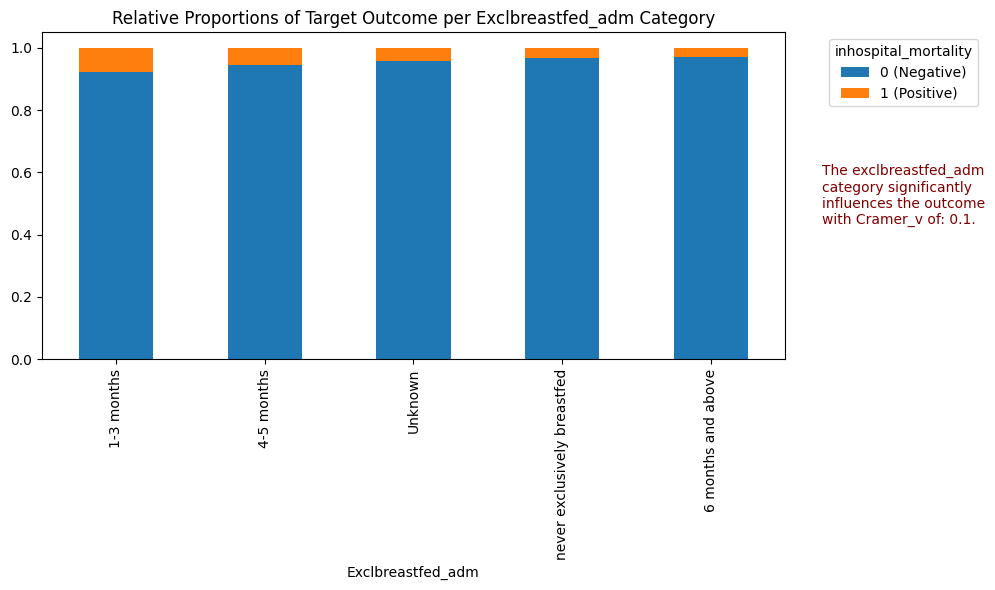

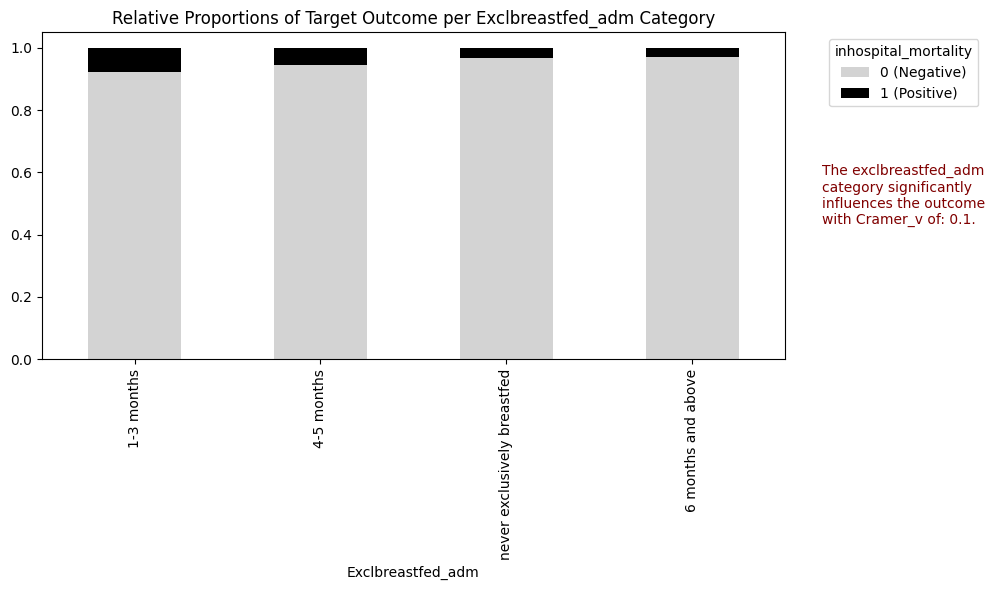

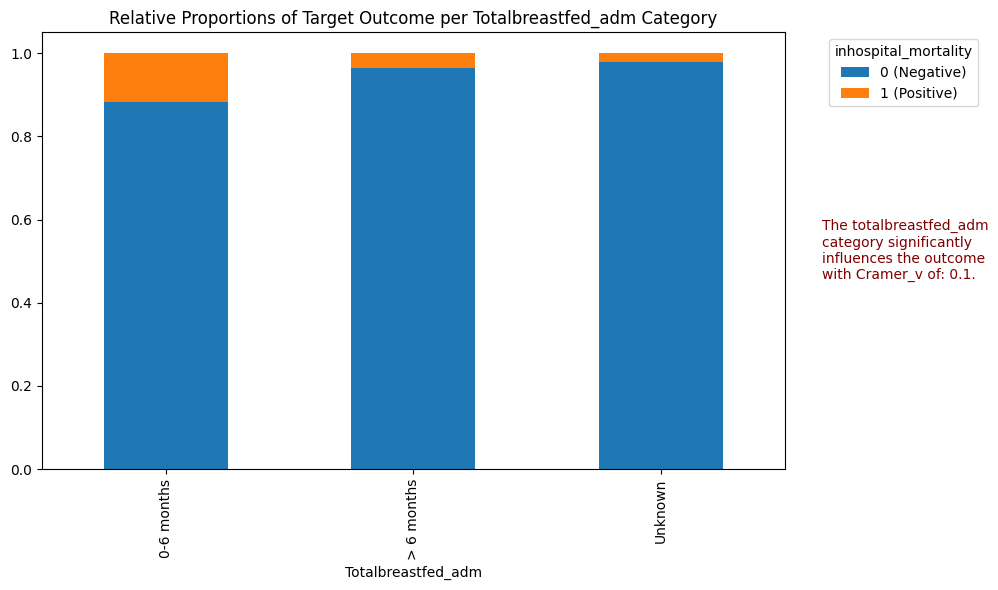

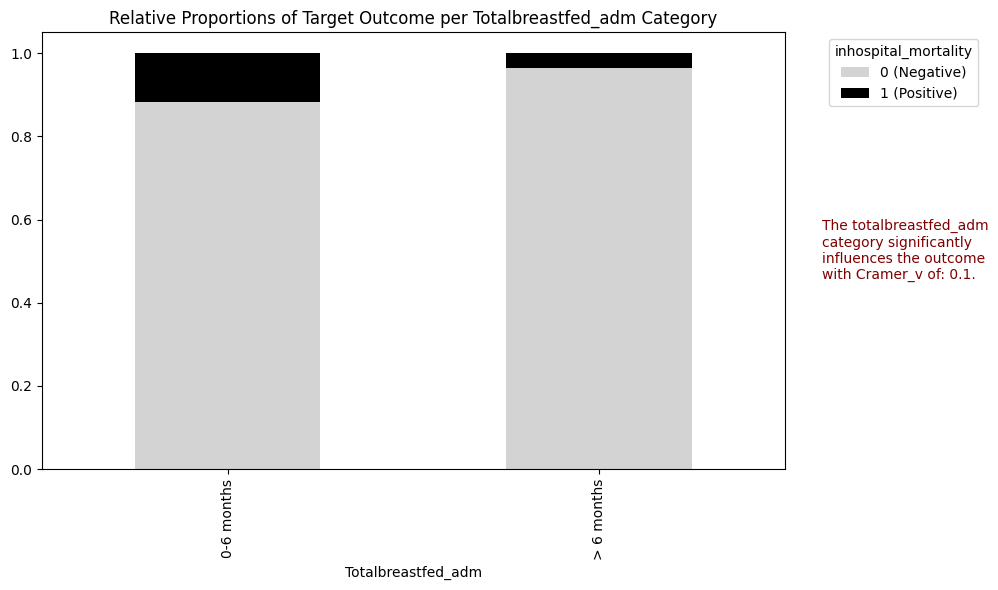

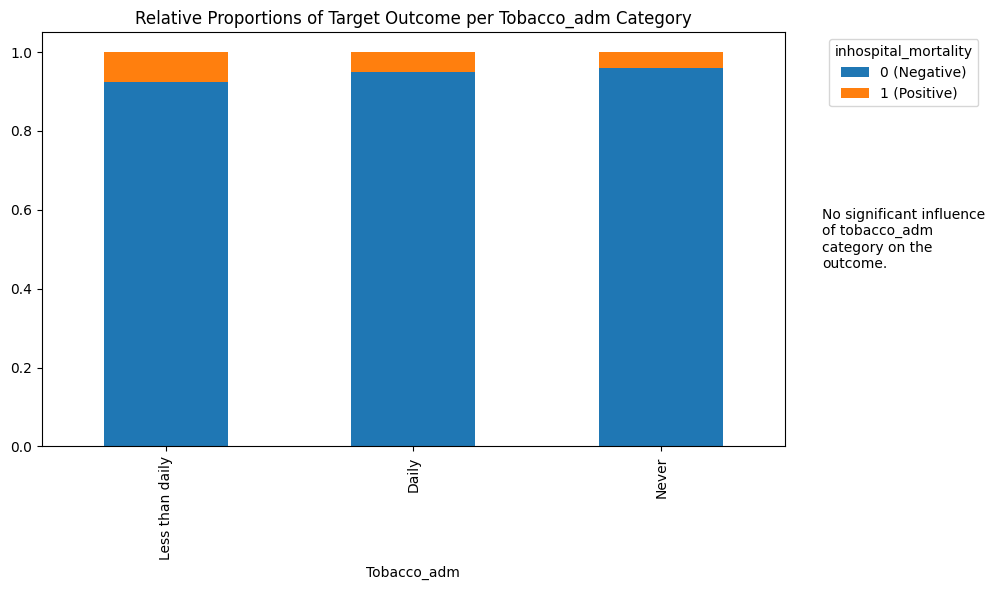

In [6]:
default_values = {'exclbreastfed_adm': 'Unknown',
            'totalbreastfed_adm': 'Unknown',
            'vaccmeaslessource_adm': 'Self report',
            'vaccpneumocsource_adm': 'Self report',
            'vaccdptsource_adm': 'Self report',
            'vaccpneumoc_adm': 'Unknown',
            'vaccmeasles_adm': 'Unknown',
            'vaccdpt_adm': 'Unknown',
            'priorweekantimal_adm': 'Dont know',
            'priorhosp_adm': 'Dont know',
            'prioryearwheeze_adm': 'Dont know',
            'travelmethod_adm': 'Other',
            'badhealthduration_adm': 'Unknown',
            'caregiver_adm_new': 'Other',
            'momhiv_adm': 'Unknown',
            'lightfuel_adm': 'Other',
            'momagefirstpregknown_adm': 'No',
            'waterpure_adm': 'No',
            'bednet_adm': 'Never'}

for col in ["exclbreastfed_adm", "totalbreastfed_adm", "tobacco_adm"]:
    categorical_analysis(col, df, target)
    if col in default_values.keys():
        tmp = df[df[col]!=default_values[col]]
        categorical_analysis(col, tmp, target, color=['#D3D3D3', '#000000'])

In [7]:
transformer = FeatureTransformer()
X, y = df.drop(columns=[target]), df[target]
transformer.fit(X)
X_transformed = transformer.transform(X)
X_transformed.head()

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,lightfuel_adm_Other,lightfuel_adm_Other (specify):,lightfuel_adm_Solar lantern,lightfuel_adm_Solar powered bulbs,lightfuel_adm_Tadooba,badhealthduration_adm_1 week - 1 month,badhealthduration_adm_< 1 week,badhealthduration_adm_> 1 year,badhealthduration_adm_In good health prior to this illness,badhealthduration_adm_Unknown
0,0.673338,0.632429,0.512887,1.492372,0.299546,-0.760001,-0.670314,-0.515764,1.010533,0.517016,...,False,False,False,True,False,False,False,False,True,False
1,0.367104,0.829668,1.593994,1.115364,0.065687,-1.098416,0.577809,0.396115,-0.780378,0.517016,...,False,False,False,False,True,False,False,False,True,False
2,0.642715,0.426224,0.512887,0.738355,1.546797,-0.218537,0.661017,1.034429,-0.382398,-3.183328,...,False,False,False,False,False,False,False,False,True,False
3,0.145084,0.381397,0.116481,0.110007,-0.051243,0.187561,-2.251269,-1.245266,0.712048,-1.735368,...,False,False,False,False,True,False,False,False,True,False
4,-0.153495,-0.066874,-0.207851,0.235677,1.079078,1.405854,0.244976,0.578490,-0.780378,0.356131,...,False,False,False,False,True,False,False,False,True,False


In [8]:
selected_cols = ['agecalc_adm' 'admitabx_adm___8', 'bcsmotor_adm', 'bcsverbal_adm',
 'bednet_adm', 'feedingstatus_adm', 'diarrheaoften_adm',
 'bcgscar_adm', 'bcseye_adm', 'lactate_mmolpl_adm', 
 'respdistress_adm', 'spo2onoxy_adm', 'symptoms_adm___15', 
 'symptoms_adm___3', 'waterpure_adm', 'weight_kg_adm',
 'exclbreastfed_adm', 'totalbreastfed_adm', 'tobacco_adm']

train_cols, hot_encoded_cols = [], []
for col in selected_cols:
    if col in X_transformed.columns.tolist():
        train_cols.append(col)
    else:
        hot_encoded_cols.append(col)
hot_encoded_cols = tuple(hot_encoded_cols)
for col in X_transformed.columns.tolist():
    if col.startswith(hot_encoded_cols):
        train_cols.append(col)
train_cols

['bcsmotor_adm',
 'bcsverbal_adm',
 'bednet_adm',
 'feedingstatus_adm',
 'diarrheaoften_adm',
 'bcgscar_adm',
 'bcseye_adm',
 'lactate_mmolpl_adm',
 'respdistress_adm',
 'spo2onoxy_adm',
 'symptoms_adm___15',
 'symptoms_adm___3',
 'waterpure_adm',
 'weight_kg_adm',
 'exclbreastfed_adm_4-5 months',
 'exclbreastfed_adm_6 months and above',
 'exclbreastfed_adm_Unknown',
 'exclbreastfed_adm_never exclusively breastfed',
 'totalbreastfed_adm_> 6 months',
 'totalbreastfed_adm_Unknown',
 'tobacco_adm_Less than daily',
 'tobacco_adm_Never']

In [30]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold

def train_model(columns=train_cols, limit_kfold_3=True, return_feature_importance=False):

    X = X_transformed.copy()[columns]
    
    kf = KFold(n_splits=5, shuffle=True, random_state=42)  # 5-fold CV
    total_recall, total_f1 = 0, 0
    num_folds = 0  # Track folds used

    # Store feature importances (averaged across folds)
    feature_importance_list = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X)): 
        if limit_kfold_3 and fold >= 3:  # Limit training to 3 passes for efficiency
            break

        # Train-test split within this fold
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Train the logistic regression model
        model = LogisticRegression(class_weight='balanced', solver='liblinear')
        model.fit(X_train, y_train)

        # Predictions
        y_pred = model.predict(X_val)

        # Evaluation metrics
        report = classification_report(y_val, y_pred, output_dict=True)
        recall_class_1 = report['1']['recall']
        f1_class_1 = report['1']['f1-score']

        # Accumulate scores
        total_recall += recall_class_1
        total_f1 += f1_class_1
        num_folds += 1

        # Store feature importance
        feature_importance_list.append(model.coef_[0])

    # Compute average scores across folds
    avg_recall = total_recall / num_folds
    avg_f1 = total_f1 / num_folds

    # Compute average feature importance
    avg_feature_importance = np.mean(feature_importance_list, axis=0)

    # Convert to DataFrame
    feature_importance_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': avg_feature_importance})
    feature_importance_df = feature_importance_df.sort_values(by='Coefficient', ascending=False)

    if return_feature_importance:
        return feature_importance_df
    else:
        return avg_recall, avg_f1
    
def plot_scores(n_vs_score):
    score_df = pd.DataFrame.from_dict(n_vs_score, orient='index', columns=['Recall', 'F1-score'])
    score_df_sorted = score_df.sort_values(by='Recall', ascending=False)

    # Plot recall and F1-score vs the combinations (first 10 for clarity)
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.plot(range(10), score_df_sorted['Recall'][:10], 'o', color='blue', label='Recall (Class 1)')
    ax1.set_xlabel('Combination Index')
    ax1.set_ylabel('Recall (Class 1)', color='blue')
    ax1.set_ylim(0.6, 1.0)
    ax1.tick_params(axis='y', labelcolor='blue')

    ax2 = ax1.twinx()
    ax2.plot(range(10), score_df_sorted['F1-score'][:10], 'x', color='green', label='F1-score (Class 1)')
    ax2.set_ylabel('F1-score (Class 1)', color='green')
    ax2.set_ylim(0.1, 0.5)
    ax2.tick_params(axis='y', labelcolor='green')

    plt.title('Recall and F1-score for Feature Combinations (with Cross-Validation)')
    ax1.grid(True)
    plt.tight_layout()
    plt.show()
    return score_df_sorted

In [33]:
feature_importance = train_model(return_feature_importance=True, limit_kfold_3=False)
feature_importance['Abs_Coefficient'] = feature_importance['Coefficient'].abs()
feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

,Feature,Coefficient,Abs_Coefficient
19,totalbreastfed_adm_Unknown,-1.864525,1.864525
17,exclbreastfed_adm_never exclusively breastfed,-1.479260,1.479260
9,spo2onoxy_adm,-1.405668,1.405668
10,symptoms_adm___15,1.213154,1.213154
1,bcsverbal_adm,1.189400,1.189400
18,totalbreastfed_adm_> 6 months,-1.042511,1.042511
5,bcgscar_adm,-1.033036,1.033036
6,bcseye_adm,-0.706804,0.706804
0,bcsmotor_adm,0.504583,0.504583
12,waterpure_adm,-0.474991,0.474991


In [25]:
feature_importance = train_model(return_feature_importance=True, limit_kfold_3=False)
feature_importance['Abs_Coefficient'] = feature_importance['Coefficient'].abs()
feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

,Feature,Coefficient,Abs_Coefficient
19,totalbreastfed_adm_Unknown,-1.569343,1.569343
17,exclbreastfed_adm_never exclusively breastfed,-1.343369,1.343369
1,bcsverbal_adm,1.309026,1.309026
9,spo2onoxy_adm,-1.278090,1.278090
10,symptoms_adm___15,1.237380,1.237380
18,totalbreastfed_adm_> 6 months,-1.132995,1.132995
5,bcgscar_adm,-1.011957,1.011957
6,bcseye_adm,-0.713834,0.713834
12,waterpure_adm,-0.575326,0.575326
20,tobacco_adm_Less than daily,-0.532287,0.532287


  0%|          | 0/3 [00:00<?, ?it/s]

Processing 7-feature sets:   0%|          | 0/6435 [00:00<?, ?it/s]

Processing 8-feature sets:   0%|          | 0/6435 [00:00<?, ?it/s]

Processing 9-feature sets:   0%|          | 0/5005 [00:00<?, ?it/s]

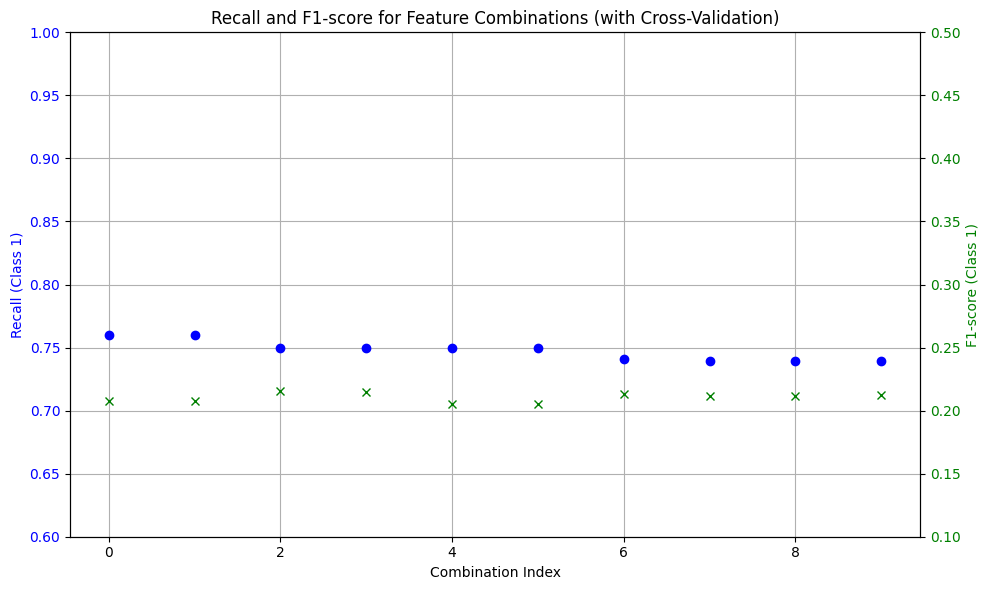

,Recall,F1-score
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, spo2onoxy_adm, symptoms_adm___15, totalbreastfed_adm_> 6 months, bcgscar_adm, bcsmotor_adm, exclbreastfed_adm_Unknown)",0.760356,0.207467
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, spo2onoxy_adm, symptoms_adm___15, totalbreastfed_adm_> 6 months, bcgscar_adm, bcsmotor_adm)",0.760356,0.207487
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, bcsverbal_adm, spo2onoxy_adm, symptoms_adm___15, totalbreastfed_adm_> 6 months, bcgscar_adm)",0.749830,0.215411
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, bcsverbal_adm, spo2onoxy_adm, symptoms_adm___15, totalbreastfed_adm_> 6 months, bcgscar_adm, bcsmotor_adm)",0.749830,0.214613
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, spo2onoxy_adm, symptoms_adm___15, totalbreastfed_adm_> 6 months, bcgscar_adm, tobacco_adm_Less than daily, bcsmotor_adm)",0.749830,0.204948


,Recall,F1-score
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, bcsverbal_adm, symptoms_adm___15, bcseye_adm, tobacco_adm_Less than daily, exclbreastfed_adm_6 months and above)",0.369572,0.268992
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, bcsverbal_adm, symptoms_adm___15, tobacco_adm_Less than daily, exclbreastfed_adm_6 months and above, exclbreastfed_adm_Unknown)",0.369572,0.266238
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, symptoms_adm___15, totalbreastfed_adm_> 6 months, bcseye_adm, waterpure_adm, tobacco_adm_Less than daily)",0.496761,0.265175
"(totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, bcsverbal_adm, bcseye_adm, tobacco_adm_Less than daily, bcsmotor_adm, exclbreastfed_adm_6 months and above)",0.369572,0.263823
"(totalbreastfed_adm_Unknown, bcsverbal_adm, symptoms_adm___15, bcseye_adm, tobacco_adm_Less than daily, bcsmotor_adm, exclbreastfed_adm_6 months and above)",0.369572,0.261828


In [32]:
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import math
from tqdm.notebook import tqdm  # Use tqdm.notebook for Jupyter
from sklearn.model_selection import KFold

# Select top N features based on absolute coefficient values
N = 15
top_N_features = feature_importance.sort_values(by='Abs_Coefficient', ascending=False).head(N).Feature.values

# Dictionary to store results
n_vs_score = {}

# Loop over different feature set sizes 
for k in tqdm(range(7, 10)):
    combinations = list(itertools.combinations(top_N_features, k))
    num_combinations = math.comb(N, k)

    for combination in tqdm(combinations, total=num_combinations, desc=f"Processing {k}-feature sets"):
        recall, f1 = train_model(list(combination), limit_kfold_3=False)
        n_vs_score[combination] = [recall, f1]

score_df_sorted = plot_scores(n_vs_score)
display(score_df_sorted[:5])
display(score_df_sorted.sort_values(by="F1-score", ascending=False)[:5])


19	totalbreastfed_adm_Unknown	-1.569343	1.569343
17	exclbreastfed_adm_never exclusively breastfed	-1.343369	1.343369
1	bcsverbal_adm	1.309026	1.309026
9	spo2onoxy_adm	-1.278090	1.278090
10	symptoms_adm___15	1.237380	1.237380
18	totalbreastfed_adm_> 6 months	-1.132995	1.132995
5	bcgscar_adm	-1.011957	1.011957
6	bcseye_adm	-0.713834	0.713834
12	waterpure_adm	-0.575326	0.575326
20	tobacco_adm_Less than daily	-0.532287	0.532287

## Fine-tuning the Golden Features

In [43]:
golden_features = ['totalbreastfed_adm_Unknown', 'exclbreastfed_adm_never exclusively breastfed', 
                   'bcsverbal_adm', 
                   'spo2onoxy_adm', 'symptoms_adm___15', 
                   'totalbreastfed_adm_> 6 months', 'bcgscar_adm', 'bcseye_adm', 
                   'waterpure_adm', 'tobacco_adm_Less than daily']

train_model(golden_features, limit_kfold_3=False)

(0.6845463461024102, 0.22219918050221704)

**Next steps**: 

1. Save the model.
2. Save the filtetered dataset with the best performing features.
3. Evaluate the model on the Leaderboard.

totalbreastfed_adm_Unknown, exclbreastfed_adm_never exclusively breastfed, spo2onoxy_adm, bcseye_adm, tobacco_adm_Less than daily, exclbreastfed_adm_6 months and above, exclbreastfed_adm_Unknown